In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
def cure_dataset(df: pd.DataFrame):
    rename_data = df[["P_max", "cN2_max", "L_inj", "dip_frac", "x_of", "plane_mm",
                        "mean_ux", "mean_uy", "mean_uz", "q_tot_pC"]].copy()

    rename_data["mean_zeta"] = df["mean_zeta_um"]
    rename_data["mean_y"] = df["mean_y_um"]
    rename_data["mean_z"] = df["mean_z_um"]
    rename_data["sigma_zeta"] = np.sqrt(df["cov_00"])
    rename_data["sigma_y"] = np.sqrt(df["cov_11"])
    rename_data["sigma_z"] = np.sqrt(df["cov_22"])
    rename_data["sigma_ux"] = np.sqrt(df["cov_33"])
    rename_data["sigma_uy"] = np.sqrt(df["cov_44"])
    rename_data["sigma_uz"] = np.sqrt(df["cov_55"])

    rename_data.dropna(inplace=True)

    return rename_data

In [3]:
def normalize_dataset(df: pd.DataFrame):
    df_mean = df.mean()
    df_std = df.std()
    norm_df = (df - df_mean) / (df_std)

    return norm_df, df_mean, df_std

In [4]:
# Load and cure data
PACK = "C:/Users/mpintonato/Desktop/Hackathon/artifact-hackathon-2026/challenges/surrogate-models/data/sample"
data = cure_dataset(pd.read_parquet(f"{PACK}/campaign_B_moments.parquet"))
norm_data, data_mean, data_std = normalize_dataset(data)

# Find GPU devices to train on if any else cpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Set device to {device}")

Set device to cpu


In [5]:
# Split data between FEATURES and TARGETS
FEATURES = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of", "plane_mm"]
TARGETS = ["mean_zeta", "mean_y", "mean_z",
           "mean_ux", "mean_uy", "mean_uz",
           "sigma_zeta", "sigma_y", "sigma_z",
           "sigma_ux", "sigma_uy", "sigma_uz",
           "q_tot_pC"]

In [6]:
# Convert dataframe to tensor
torch_features = torch.tensor(norm_data[FEATURES].to_numpy(), device=device, dtype=torch.float32)
torch_targets = torch.tensor(norm_data[TARGETS].to_numpy(), device=device, dtype=torch.float32)

# Split train / test
X_train, X_test, Y_train, Y_test = train_test_split(torch_features, torch_targets, test_size=0.15, random_state=0)

In [7]:
# Create VAE model
def mlp(sizes):
    layers = []
    for a, b in zip(sizes[:-2], sizes[1:-1]):
        layers += [nn.Linear(a, b), nn.ReLU()]
    layers.append(nn.Linear(sizes[-2], sizes[-1]))
    return nn.Sequential(*layers)

class VAE(nn.Module):
    def __init__(self, n_in, n_out, hidden=(256, 64, 16), latent=2):
        super(VAE, self).__init__()

        self.enc = mlp([n_in, *hidden])
        self.mu = nn.Linear(hidden[-1], latent)
        self.logvar = nn.Linear(hidden[-1], latent)
        self.dec = mlp([latent, *hidden[::-1], n_out])


    def forward(self, x):
        e = self.enc(x)
        mu, logvar = self.mu(e), self.logvar(e)
        z = mu + torch.randn_like(mu) * torch.exp(0.5*logvar)
        return self.dec(z), mu, logvar

    @torch.no_grad()
    def predict(self, X):
        return model.dec(model.mu(model.enc(X)))

In [8]:
# Setup VAE loss function with KL loss
def loss_fn(y_pred, y_true, mu, logvar):
    c_loss = torch.square(y_pred - y_true).sum(-1).mean()
    kl_loss = (-0.5 * (1 + logvar - torch.square(mu) - torch.exp(logvar)).sum(-1)).mean()

    return c_loss + 1e-3*kl_loss, c_loss, kl_loss

In [9]:
# Setup Hyperparameters
EPOCHS = 5
LR = 1e-3
DATA_SIZE = X_train.shape[0]
BATCH_SIZE = 1024

In [10]:
# Setup VAE
model = VAE(n_in=len(FEATURES), n_out=len(TARGETS), hidden=(512, 128, 32), latent=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# Start training VAE
print("Start training VAE")
pbar = tqdm(range(EPOCHS), desc="VAE")
loss_arr = {"train": [], "test": []}

for epoch in pbar:
    tot, n = 0., 0
    # Shuffle dataset
    random_idx = torch.randperm(DATA_SIZE, device=device)
    model.train()
    # Training loop
    for start in range(0, DATA_SIZE, BATCH_SIZE): # manually indexing batch size
        idx = random_idx[start : start + BATCH_SIZE]
        x, y = X_train[idx], Y_train[idx]
        optimizer.zero_grad()
        y_pred, mu, logvar = model(x)
        loss, recon, kl = loss_fn(y_pred, y, mu, logvar)
        loss.backward()
        optimizer.step()
        tot += recon.item() * len(x)
        n += len(x)

    # Eval loop
    if epoch%5==0:
        model.eval()
        with torch.no_grad():
            pred = model.dec(model.mu(model.enc(X_test)))
            per_target = torch.square(pred - Y_test).mean(0)

        # Print info
        mse = ((model.predict(X_test) - Y_test) ** 2).mean(0)
        pbar.set_postfix(train=f"{tot / n / len(TARGETS):.4f}", test=f"{mse.mean():.3f}")
        loss_arr["train"].append(tot / n / len(TARGETS))
        loss_arr["test"].append(mse.mean())

    sched.step()

Start training VAE


VAE: 100%|██████████| 5/5 [00:00<00:00,  7.98it/s, test=0.681, train=0.8970]


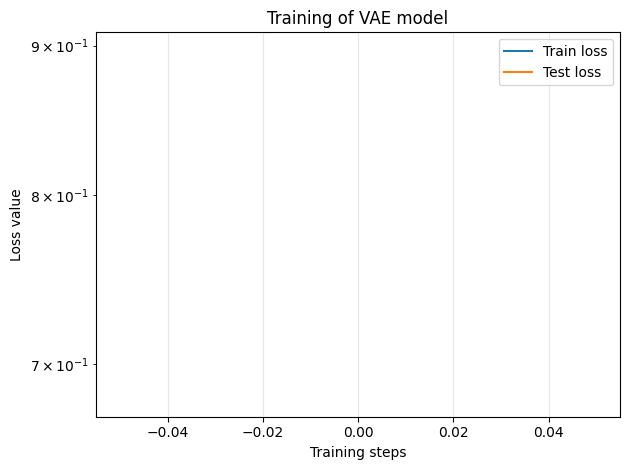

In [11]:
# Plot training loss
x = np.arange(len(loss_arr["test"]))
fig, ax = plt.subplots()
ax.semilogy(x,loss_arr["train"], label="Train loss")
ax.semilogy(x,loss_arr["test"], label="Test loss")
ax.legend()
ax.grid(alpha=0.3)
ax.set_xlabel("Training steps")
ax.set_ylabel("Loss value")
ax.set_title("Training of VAE model")
fig.tight_layout()
plt.show()

In [12]:
# Compute prediction of the trained model
model.eval()
pred = model.predict(X_test)
y_true = Y_test.cpu().numpy()
y_pred = pred.cpu().numpy()

# Compute R² score
r2 = r2_score(y_true, y_pred, multioutput="raw_values")
for col, s in zip(TARGETS, r2):
    print(f"{col:12s} R² = {s:.3f}")
print(f"{'mean':12s} R² = {r2.mean():.3f}")

mean_zeta    R² = 0.540
mean_y       R² = 0.021
mean_z       R² = -0.007
mean_ux      R² = 0.831
mean_uy      R² = 0.002
mean_uz      R² = -0.002
sigma_zeta   R² = 0.806
sigma_y      R² = 0.789
sigma_z      R² = 0.766
sigma_ux     R² = 0.823
sigma_uy     R² = 0.838
sigma_uz     R² = 0.811
q_tot_pC     R² = 0.907
mean         R² = 0.548


In [14]:
# Normalize test FEATURES with the TRAIN stats
test_norm = (test_inputs[FEATURES] - data_mean[FEATURES]) / data_std[FEATURES]
test_features = torch.tensor(test_norm.to_numpy(), device=device, dtype=torch.float32)

# Predict (normalized target space)
model.eval()
test_pred = model.predict(test_features).cpu().numpy()   # shape (n, 13)

# Build df: columns, not rows
df_pred = pd.DataFrame(test_pred, columns=TARGETS)

# Denormalize with TRAIN target stats
submission = df_pred * data_std[TARGETS].values + data_mean[TARGETS].values
submission.insert(0, "config", test_inputs["config"].values)
submission.insert(1, "plane_mm", test_inputs["plane_mm"].values)
submission.to_csv("submission_campaign_B_moments.csv", index=False)
print(f"submission_campaign_B_moments.csv  ({len(submission):,} rows)")
submission.head()

submission_campaign_B_moments.csv  (3,213 rows)


,config,plane_mm,mean_zeta,mean_y,mean_z,mean_ux,mean_uy,mean_uz,sigma_zeta,sigma_y,sigma_z,sigma_ux,sigma_uy,sigma_uz,q_tot_pC
0,1002,2.1,-17.365151,0.044261,-0.007685,86.789976,0.003529,-0.001336,4.107735,9.864423,8.004739,31.467821,3.330133,2.081011,186.083564
1,1002,2.3,-17.846293,0.039466,-0.007742,112.602244,0.009707,-0.001754,4.371795,12.689521,9.893877,40.819678,3.470295,2.165838,197.476164
2,1002,2.5,-18.278860,0.033676,-0.008681,143.530299,0.012986,-0.001008,4.611289,15.571623,11.836644,51.125247,3.531967,2.192406,206.448974
3,1002,2.7,-18.637862,0.028038,-0.008489,173.199724,0.014620,-0.000119,4.817266,18.205445,13.568549,60.982016,3.554976,2.201760,212.178515
4,1002,2.9,-18.908678,0.011238,-0.006226,211.280668,0.012565,-0.000578,4.948252,21.005119,15.120002,71.785233,3.452107,2.151534,210.819356
